| Eksperimen | Target | Faktor | Kombinasi |
|---|---|---|---|
| 1 | Kesediaan **sangat kuat** (skor 4) vs lainnya | 9 algoritma × 6 set fitur | 54 |
| 2 | **Tidak bersedia** (skor 1–2), minoritas ±9% | 9 algoritma × 5 strategi (None, RUS, ROS, SMOTE, *cost-sensitive*) | 42 |
| 3 | Target eksperimen 1 | 9 algoritma dengan *nested CV tuning* | 9 |
| 4 | Target 1 | Penjelasan model dengan **SHAP** | – |
| 5 | Target 1 | **Ablasi** kelompok fitur | 7 |
| 6 | Target 2 | **Kalibrasi** probabilitas dan **pemilihan ambang** bersarang | – |
| 7 | Target 1 dan 2 | **Keadilan** performa antara dosen dan mahasiswa | – |
| 8 | Target 1 | **Learning curve** | – |

**Algoritma:** LR, KNN, NB, DT, SVM, RF, Histogram Gradient Boosting (GB), MLP, **CatBoost (CAT)**.

In [24]:
# ===== 1. Persiapan =====
import warnings, json, os, time
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.metrics import (make_scorer, matthews_corrcoef, roc_auc_score, f1_score, balanced_accuracy_score,
                             average_precision_score)
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.model_selection import learning_curve, cross_val_predict
from sklearn.metrics import brier_score_loss, recall_score, precision_score
from catboost import CatBoostClassifier
import shap
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

DATA_PATH = 'dataset.xlsx'
OUT_DIR = 'outputs_resti2'; os.makedirs(OUT_DIR, exist_ok=True)
SEED = 42; N_JOBS = -1
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False})
print('Siap.')

Siap.


## 2. Pemuatan, pembersihan, dan anonimisasi data

Aturan kelayakan sama dengan studi sebelumnya: hanya dosen dan mahasiswa (sesuai surat etik), dan hanya responden yang pernah memakai LMS.
Kolom identitas (nama kampus, lokasi, timestamp) dihapus.

In [25]:
raw = pd.read_excel(DATA_PATH)
raw = raw.sort_values(raw.columns[0]).reset_index(drop=True); col = list(raw.columns)
role = raw[col[2]].astype(str).str.lower()
is_lec, is_stu = role.str.contains('dosen'), role.str.contains('mahasiswa|taruna|taruni')
dur = raw[col[5]].astype(str).str.strip().str.lower()
real_platform = raw[col[6]].astype(str).str.contains('Moodle|Classroom|SPADA')
never = dur.str.contains('tidak pernah|belum pernah|tdk pernah|belum menggunakan|gaada') | (dur.isin(['-', '0']) & ~real_platform)
keep = (is_lec | is_stu) & ~never
audit = {'submitted': len(raw), 'outside_approved_roles': int((~(is_lec | is_stu)).sum()),
         'never_used_lms': int(((is_lec | is_stu) & never).sum()), 'eligible': int(keep.sum())}
df = raw[keep].drop(columns=[col[0], col[1], col[3], col[4]]).copy()
df['is_lecturer'], df['is_student'] = is_lec[keep], is_stu[keep]
audit

{'submitted': 610,
 'outside_approved_roles': 7,
 'never_used_lms': 21,
 'eligible': 582}

## 3. Konstruksi fitur

Enam kelompok fitur:
- **Current** (7 butir kondisi LMS saat ini), **Desired** (9 butir fitur yang diinginkan), **Benefit** (5 butir persepsi manfaat)
- **Profile**: peran, lama memakai LMS, kualitas internet, perangkat, platform
- **Checklist**: 26 indikator biner (kendala, prioritas fitur, karakteristik LMS ideal)

In [26]:
def to_num(s):
    v = pd.to_numeric(s.astype(str).str.strip(), errors='coerce'); return v.where(v.isin([1, 2, 3, 4]))
NAMES = {8: 'Cur: online attendance', 9: 'Cur: activity monitoring', 10: 'Cur: integrated assignments', 11: 'Cur: collaboration',
         12: 'Cur: analytics/reporting', 13: 'Cur: video-conference integration', 14: 'Cur: ease of use',
         16: 'Des: video-conference integration', 17: 'Des: automatic attendance', 18: 'Des: real-time monitoring',
         19: 'Des: deadline management', 20: 'Des: activity-based assessment', 21: 'Des: real-time collaboration',
         22: 'Des: analytics dashboard', 23: 'Des: automatic notifications', 24: 'Des: automatic reports',
         28: 'Ben: improves learning quality', 29: 'Ben: analytics helps lecturers', 30: 'Ben: collaboration improves interaction',
         31: 'Ben: LMS-meeting integration', 32: 'Ben: data-driven LMS needed'}
R_ = pd.DataFrame({n: to_num(df[col[k]]) for k, n in NAMES.items()}, index=df.index)
R_['willingness'] = to_num(df[col[27]])
CUR = [n for n in NAMES.values() if n.startswith('Cur')]; DES = [n for n in NAMES.values() if n.startswith('Des')]
BEN = [n for n in NAMES.values() if n.startswith('Ben')]
d_ = df[col[5]].astype(str).str.strip().str.lower(); net = df[col[26]].fillna('').astype(str)   # 1 jawaban kosong -> diisi modus 'Baik' (3)
dev = df[col[25]].fillna('').astype(str); plat = df[col[6]].fillna('').astype(str)
PROF = pd.DataFrame({'Prof: lecturer': (df.is_lecturer & ~df.is_student).astype(int),
                     'Prof: LMS use < 1 year': (d_ == '< 1 tahun').astype(int),
                     'Prof: LMS use > 3 years': d_.isin(['> 3 tahun', '4 tahun', '7 tahun', '> 4', '> 4 tahun']).astype(int),
                     'Prof: internet quality': net.map(lambda x: 4 if x.startswith('Sangat') else 3 if (x.startswith('Baik') or x == '') else 2 if x.startswith('Tidak') else 1),
                     'Prof: smartphone': dev.str.contains('Smartphone').astype(int), 'Prof: laptop': dev.str.contains('Laptop').astype(int),
                     'Prof: tablet': dev.str.contains('Tablet').astype(int), 'Prof: Moodle/internal LMS': plat.str.contains('Moodle').astype(int),
                     'Prof: Google Classroom': plat.str.contains('Classroom').astype(int)}, index=df.index)
CHECK = {15: {'Sulit memantau': 'Gap: monitoring', 'Presensi tatap maya': 'Gap: manual attendance', 'Interaksi kolaboratif': 'Gap: collaboration',
              'LMS dan video conference': 'Gap: LMS-VC separated', 'Tidak tersedia fitur analitik': 'Gap: no analytics',
              'Penugasan dan penilaian': 'Gap: assignments', 'Data aktivitas': 'Gap: activity data', 'LMS sulit digunakan': 'Gap: difficult LMS'},
         33: {'Presensi otomatis': 'Pri: auto attendance', 'Pengelolaan tugas': 'Pri: deadlines', 'Monitoring keaktifan': 'Pri: monitoring',
              'Tampilan sederhana': 'Pri: simple UI', 'Forum diskusi': 'Pri: discussion', 'Laporan pembelajaran': 'Pri: reports',
              'Notifikasi otomatis': 'Pri: notifications', 'Penilaian berbasis': 'Pri: activity assessment', 'Dashboard analitik': 'Pri: dashboard',
              'Integrasi LMS dengan': 'Pri: VC integration'},
         34: {'Dapat diakses': 'Char: cross-device', 'Aman dan menjaga': 'Char: privacy', 'Terintegrasi dalam': 'Char: single platform',
              'Mudah dipelajari': 'Char: learnable', 'Mendukung pembelajaran kolaboratif': 'Char: collaborative', 'Hemat kuota': 'Char: low data',
              'Adaptif': 'Char: adaptive', 'Berbasis data': 'Char: data-driven'}}
CHK = pd.concat([pd.DataFrame({lab: df[col[k]].fillna('').astype(str).str.contains(key, regex=False).astype(int)
                               for key, lab in m.items()}, index=df.index) for k, m in CHECK.items()], axis=1)
data = pd.concat([R_, PROF, CHK], axis=1).dropna(subset=CUR + DES + BEN + ['willingness']).reset_index(drop=True)
FEATURE_SETS = {'FS1 Current': CUR, 'FS2 Desired': DES, 'FS3 Benefit': BEN, 'FS4 Current+Desired': CUR + DES,
                'FS5 Current+Desired+Benefit': CUR + DES + BEN, 'FS6 All features': CUR + DES + BEN + list(PROF.columns) + list(CHK.columns)}
print('Sampel lengkap:', len(data)); print({k: len(v) for k, v in FEATURE_SETS.items()})
print('Distribusi kesediaan:', data.willingness.value_counts().sort_index().to_dict())

Sampel lengkap: 539
{'FS1 Current': 7, 'FS2 Desired': 9, 'FS3 Benefit': 5, 'FS4 Current+Desired': 16, 'FS5 Current+Desired+Benefit': 21, 'FS6 All features': 56}
Distribusi kesediaan: {1.0: 10, 2.0: 39, 3.0: 233, 4.0: 257}


## 4. Variabel target

- **Target A (eksperimen 1 dan 3):** `strong_willingness` = 1 jika skor kesediaan = 4, selain itu 0. Kelasnya relatif seimbang.
- **Target B (eksperimen 2):** `unwilling` = 1 jika skor kesediaan 1–2. Ini kelas minoritas (±9%), jadi diperlukan teknik penanganan data tidak seimbang.

In [27]:
yA = (data.willingness == 4).astype(int).values
yB = (data.willingness <= 2).astype(int).values
print('Target A — positif:', yA.sum(), f'({yA.mean()*100:.1f}%)'); print('Target B — positif:', yB.sum(), f'({yB.mean()*100:.1f}%)')

Target A — positif: 257 (47.7%)
Target B — positif: 49 (9.1%)


## 5. Definisi algoritma dan protokol evaluasi

Setiap model dibungkus dalam *pipeline* (standardisasi → [resampling] → model), sehingga standardisasi dan resampling **hanya dipelajari dari data latih** di setiap fold.
Ini mencegah kebocoran informasi (*data leakage*).

In [28]:
CAT_P = dict(iterations=300, depth=4, learning_rate=0.05, random_seed=SEED, verbose=0, thread_count=1)
def algorithms():
    return {'LR': LogisticRegression(max_iter=5000), 'KNN': KNeighborsClassifier(n_neighbors=15), 'NB': GaussianNB(),
            'DT': DecisionTreeClassifier(max_depth=5, random_state=SEED), 'SVM': SVC(kernel='rbf', probability=True, random_state=SEED),
            'RF': RandomForestClassifier(n_estimators=300, random_state=SEED), 'GB': HistGradientBoostingClassifier(random_state=SEED),
            'MLP': MLPClassifier(hidden_layer_sizes=(32,), max_iter=2000, early_stopping=True, random_state=SEED),
            'CAT': CatBoostClassifier(**CAT_P)}
ALGS = list(algorithms())
CV = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)      # 25 fold
SCORING_A = {'roc_auc': 'roc_auc', 'f1_macro': 'f1_macro', 'accuracy': 'accuracy', 'mcc': make_scorer(matthews_corrcoef)}
print('Algoritma:', ALGS, '| Jumlah fold evaluasi:', CV.get_n_splits())

Algoritma: ['LR', 'KNN', 'NB', 'DT', 'SVM', 'RF', 'GB', 'MLP', 'CAT'] | Jumlah fold evaluasi: 25


## 6. Eksperimen 1 — Algoritma × Set fitur (54 kombinasi)

In [29]:
t0 = time.time(); exp1_rows, exp1_folds = [], {}
for fs, cols in FEATURE_SETS.items():
    X = data[cols].values.astype(float)
    for alg, model in algorithms().items():
        res = cross_validate(Pipeline([('scale', StandardScaler()), ('model', model)]), X, yA, cv=CV, scoring=SCORING_A, n_jobs=N_JOBS)
        exp1_folds[(fs, alg)] = res['test_roc_auc']
        exp1_rows.append({'feature_set': fs, 'algorithm': alg, **{f'{m}_mean': res[f'test_{m}'].mean() for m in SCORING_A},
                          **{f'{m}_sd': res[f'test_{m}'].std() for m in SCORING_A}})
exp1 = pd.DataFrame(exp1_rows); print(f'Selesai dalam {time.time()-t0:.0f} detik')
exp1.pivot(index='algorithm', columns='feature_set', values='roc_auc_mean').loc[ALGS].round(3)

Selesai dalam 10 detik


feature_set,FS1 Current,FS2 Desired,FS3 Benefit,FS4 Current+Desired,FS5 Current+Desired+Benefit,FS6 All features
algorithm,,,,,,
LR,0.612,0.683,0.721,0.690,0.743,0.741
KNN,0.656,0.678,0.713,0.712,0.755,0.759
NB,0.678,0.686,0.724,0.707,0.746,0.771
DT,0.640,0.669,0.684,0.659,0.696,0.707
SVM,0.660,0.712,0.713,0.736,0.751,0.773
RF,0.637,0.688,0.688,0.721,0.748,0.777
GB,0.650,0.690,0.707,0.699,0.710,0.753
MLP,0.568,0.668,0.707,0.695,0.730,0.705
CAT,0.655,0.681,0.702,0.719,0.740,0.768


In [30]:
print('Macro-F1:'); print(exp1.pivot(index='algorithm', columns='feature_set', values='f1_macro_mean').loc[ALGS].round(3))
print('\nMCC:'); print(exp1.pivot(index='algorithm', columns='feature_set', values='mcc_mean').loc[ALGS].round(3))
fs_mean = exp1.groupby('feature_set').roc_auc_mean.mean().sort_values(ascending=False)
alg_mean = exp1.groupby('algorithm').roc_auc_mean.mean().sort_values(ascending=False)
best_combo = exp1.sort_values('roc_auc_mean', ascending=False).iloc[0]
BEST_FS = fs_mean.index[0]
print('\nRata-rata AUC per set fitur:'); print(fs_mean.round(3))
print('\nRata-rata AUC per algoritma:'); print(alg_mean.round(3))
print('\nKombinasi terbaik:', best_combo.feature_set, '+', best_combo.algorithm, f'AUC = {best_combo.roc_auc_mean:.3f}')

Macro-F1:
feature_set  FS1 Current  FS2 Desired  FS3 Benefit  FS4 Current+Desired  \
algorithm                                                                 
LR                 0.595        0.664        0.697                0.666   
KNN                0.610        0.665        0.698                0.664   
NB                 0.615        0.670        0.696                0.684   
DT                 0.611        0.673        0.675                0.650   
SVM                0.615        0.670        0.684                0.680   
RF                 0.622        0.652        0.685                0.661   
GB                 0.619        0.658        0.687                0.654   
MLP                0.370        0.655        0.683                0.639   
CAT                0.621        0.655        0.682                0.666   

feature_set  FS5 Current+Desired+Benefit  FS6 All features  
algorithm                                                   
LR                                 0.695  

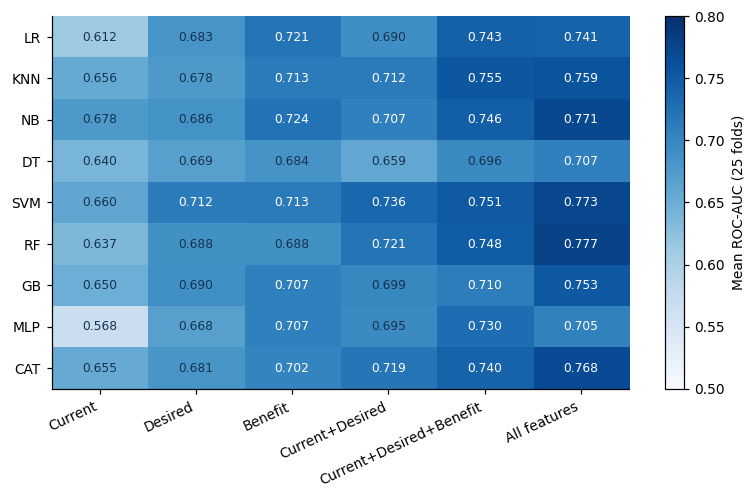

In [31]:
H = exp1.pivot(index='algorithm', columns='feature_set', values='roc_auc_mean').loc[ALGS]
fig, ax = plt.subplots(figsize=(7.2, 4.6))
im = ax.imshow(H.values, cmap='Blues', vmin=0.5, vmax=0.8, aspect='auto')
ax.set_xticks(range(H.shape[1])); ax.set_xticklabels([c.split(' ', 1)[1] for c in H.columns], rotation=25, ha='right')
ax.set_yticks(range(H.shape[0])); ax.set_yticklabels(H.index)
for i in range(H.shape[0]):
    for j in range(H.shape[1]):
        v = H.values[i, j]; ax.text(j, i, f'{v:.3f}', ha='center', va='center', fontsize=8, color='white' if v > 0.7 else '#16324f')
plt.colorbar(im, label='Mean ROC-AUC (25 folds)'); plt.tight_layout(); plt.savefig(f'{OUT_DIR}/fig_heatmap_auc.png', dpi=300); plt.show()

### Uji statistik antar-algoritma pada set fitur terbaik

- **Friedman**: apakah peringkat algoritma berbeda secara konsisten di 25 fold?
- **Nemenyi**: *critical difference* (CD) antar-peringkat rata-rata.
- ***Corrected resampled t-test*** (Nadeau–Bengio): membandingkan algoritma terbaik dengan setiap algoritma lain, dengan koreksi varians karena fold saling tumpang tindih.

Catatan: fold dari *repeated CV* tidak sepenuhnya independen, jadi uji Friedman–Nemenyi di sini bersifat deskriptif. Uji Nadeau–Bengio adalah uji yang lebih konservatif.

In [32]:
A = np.column_stack([exp1_folds[(BEST_FS, a)] for a in ALGS])         # 25 x 8
fried = stats.friedmanchisquare(*[A[:, j] for j in range(A.shape[1])])
ranks = np.vstack([stats.rankdata(-row) for row in A]); avg_rank = pd.Series(ranks.mean(axis=0), index=ALGS).sort_values()
k, Nf = A.shape[1], A.shape[0]
q_alpha = {2: 1.960, 3: 2.343, 4: 2.569, 5: 2.728, 6: 2.850, 7: 2.949, 8: 3.031, 9: 3.102, 10: 3.164, 11: 3.219, 12: 3.268}[k]
CD = q_alpha * np.sqrt(k * (k + 1) / (6 * Nf))
print(f'Friedman chi2({k-1}) = {fried.statistic:.2f}, p = {fried.pvalue:.2e}; Nemenyi CD = {CD:.3f}')
print('Peringkat rata-rata (1 = terbaik):'); print(avg_rank.round(2))
def nb_corrected_t(a, b, n_train_ratio=0.8):
    d = a - b; J = len(d); var = d.var(ddof=1)
    t = d.mean() / np.sqrt((1 / J + (1 - n_train_ratio) / n_train_ratio) * var); p = 2 * stats.t.sf(abs(t), J - 1); return t, p
best_alg = avg_rank.index[0]; nb_tests = {}
for a in ALGS:
    if a == best_alg: continue
    t, p = nb_corrected_t(exp1_folds[(BEST_FS, best_alg)], exp1_folds[(BEST_FS, a)])
    nb_tests[a] = {'mean_diff': float(exp1_folds[(BEST_FS, best_alg)].mean() - exp1_folds[(BEST_FS, a)].mean()), 't': float(t), 'p': float(p)}
print(f'\nCorrected resampled t-test: {best_alg} vs lainnya ({BEST_FS})'); print(pd.DataFrame(nb_tests).T.round(4))

Friedman chi2(8) = 108.14, p = 9.18e-20; Nemenyi CD = 2.403
Peringkat rata-rata (1 = terbaik):
RF     2.56
SVM    3.20
NB     3.40
CAT    3.68
KNN    4.64
GB     5.32
LR     6.44
DT     7.72
MLP    8.04
dtype: float64

Corrected resampled t-test: RF vs lainnya (FS6 All features)
     mean_diff       t       p
LR      0.0361  2.5603  0.0172
KNN     0.0185  1.2418  0.2263
NB      0.0061  0.4836  0.6331
DT      0.0701  2.6916  0.0128
SVM     0.0046  0.4718  0.6413
GB      0.0243  1.7070  0.1007
MLP     0.0719  3.3213  0.0029
CAT     0.0093  0.8419  0.4081


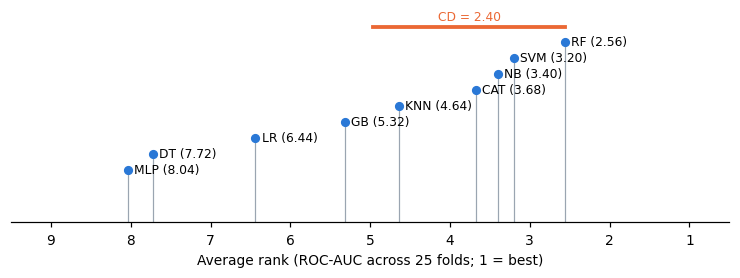

In [33]:
fig, ax = plt.subplots(figsize=(6.8, 2.6))
ax.set_xlim(0.5, k + 0.5); ax.set_ylim(0, 1); ax.invert_xaxis(); ax.get_yaxis().set_visible(False)
for s in ['left', 'right', 'top']: ax.spines[s].set_visible(False)
ax.set_xticks(range(1, k + 1)); ax.set_xlabel('Average rank (ROC-AUC across 25 folds; 1 = best)')
for i, (a, r) in enumerate(avg_rank.items()):
    y = 0.88 - i * 0.078; ax.plot([r, r], [0, y], color='#9aa5b1', lw=0.8); ax.plot(r, y, 'o', color='#2a78d6', ms=5)
    ax.text(r - 0.08, y, f'{a} ({r:.2f})', va='center', ha='right' if False else 'left', fontsize=8)
ax.plot([avg_rank.iloc[0], avg_rank.iloc[0] + CD], [0.95, 0.95], color='#eb6834', lw=2.5)
ax.text(avg_rank.iloc[0] + CD / 2, 0.97, f'CD = {CD:.2f}', ha='center', va='bottom', fontsize=8, color='#eb6834')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/fig_cd.png', dpi=300); plt.show()

## 7. Eksperimen 2 — Algoritma × Strategi penanganan data tidak seimbang (42 kombinasi)

Target B memiliki kelas minoritas sekitar 9%. Empat strategi dibandingkan, semuanya diterapkan **di dalam** fold latih:
**None** (tanpa penanganan), **RUS** (*random undersampling*), **ROS** (*random oversampling*), **SMOTE**, dan **CW** (*cost-sensitive learning*: bobot kelas seimbang; hanya untuk 6 algoritma yang mendukungnya — KNN, NB, dan MLP tidak).
Metrik utama: *balanced accuracy*, F1 kelas minoritas, MCC, dan PR-AUC. Akurasi biasa menyesatkan untuk data tidak seimbang.

In [34]:
SAMPLERS = {'None': None, 'RUS': RandomUnderSampler(random_state=SEED), 'ROS': RandomOverSampler(random_state=SEED),
            'SMOTE': SMOTE(random_state=SEED, k_neighbors=5), 'CW': 'cw'}
RATIO_B = (yB == 0).sum() / (yB == 1).sum()
def cw_model(alg):
    m = {'LR': LogisticRegression(max_iter=5000, class_weight='balanced'),
         'DT': DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=SEED),
         'SVM': SVC(kernel='rbf', probability=True, class_weight='balanced', random_state=SEED),
         'RF': RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=SEED),
         'GB': HistGradientBoostingClassifier(class_weight='balanced', random_state=SEED),
         'CAT': CatBoostClassifier(**CAT_P, auto_class_weights='Balanced')}
    return m.get(alg)
SCORING_B = {'balanced_accuracy': 'balanced_accuracy', 'f1_minority': 'f1', 'mcc': make_scorer(matthews_corrcoef),
             'pr_auc': 'average_precision', 'roc_auc': 'roc_auc', 'accuracy': 'accuracy'}
XB = data[FEATURE_SETS[BEST_FS]].values.astype(float)
t0 = time.time(); exp2_rows = []
for sname, sampler in SAMPLERS.items():
    for alg, model in algorithms().items():
        if isinstance(sampler, str):
            model = cw_model(alg)
            if model is None: continue
            steps = [('scale', StandardScaler()), ('model', model)]
        else:
            steps = [('scale', StandardScaler())] + ([('sample', sampler)] if sampler is not None else []) + [('model', model)]
        res = cross_validate(Pipeline(steps), XB, yB, cv=CV, scoring=SCORING_B, n_jobs=N_JOBS)
        exp2_rows.append({'sampler': sname, 'algorithm': alg, **{f'{m}_mean': res[f'test_{m}'].mean() for m in SCORING_B},
                          **{f'{m}_sd': res[f'test_{m}'].std() for m in SCORING_B}})
exp2 = pd.DataFrame(exp2_rows); print(f'Selesai dalam {time.time()-t0:.0f} detik  | fitur: {BEST_FS}')
print('Balanced accuracy:'); print(exp2.pivot(index='algorithm', columns='sampler', values='balanced_accuracy_mean').loc[ALGS, list(SAMPLERS)].round(3))
print('\nF1 kelas minoritas:'); print(exp2.pivot(index='algorithm', columns='sampler', values='f1_minority_mean').loc[ALGS, list(SAMPLERS)].round(3))
print('\nMCC:'); print(exp2.pivot(index='algorithm', columns='sampler', values='mcc_mean').loc[ALGS, list(SAMPLERS)].round(3))
print('\nAkurasi (perhatikan: tinggi meski minoritas tidak terdeteksi):')
print(exp2.pivot(index='algorithm', columns='sampler', values='accuracy_mean').loc[ALGS, list(SAMPLERS)].round(3))

Selesai dalam 12 detik  | fitur: FS6 All features
Balanced accuracy:
sampler     None    RUS    ROS  SMOTE     CW
algorithm                                   
LR         0.563  0.636  0.629  0.629  0.627
KNN        0.519  0.632  0.613  0.581    NaN
NB         0.653  0.661  0.652  0.655    NaN
DT         0.514  0.581  0.555  0.588  0.557
SVM        0.504  0.645  0.581  0.575  0.610
RF         0.521  0.643  0.537  0.556  0.505
GB         0.549  0.629  0.559  0.541  0.574
MLP        0.509  0.556  0.648  0.638    NaN
CAT        0.556  0.652  0.554  0.575  0.568

F1 kelas minoritas:
sampler     None    RUS    ROS  SMOTE     CW
algorithm                                   
LR         0.201  0.240  0.260  0.264  0.258
KNN        0.073  0.249  0.224  0.197    NaN
NB         0.302  0.266  0.274  0.276    NaN
DT         0.100  0.203  0.183  0.239  0.185
SVM        0.015  0.255  0.244  0.231  0.298
RF         0.082  0.251  0.139  0.189  0.021
GB         0.171  0.238  0.197  0.152  0.224
MLP       

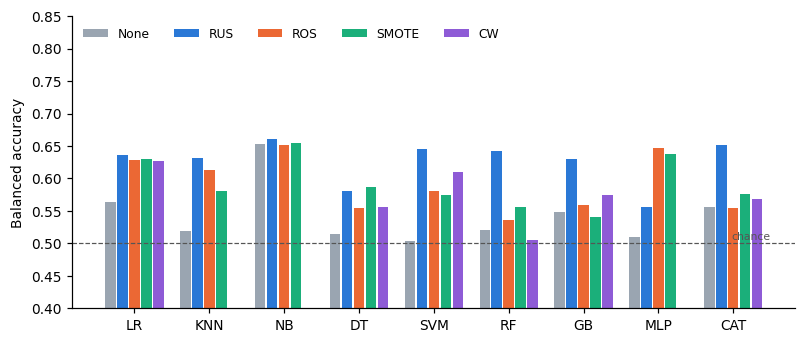

Rata-rata per teknik:
         balanced_accuracy_mean  f1_minority_mean  mcc_mean  pr_auc_mean
sampler                                                                 
None                      0.543             0.138     0.116        0.258
RUS                       0.626             0.238     0.153        0.273
ROS                       0.592             0.221     0.156        0.262
SMOTE                     0.593             0.229     0.173        0.263
CW                        0.573             0.201     0.142        0.254
Kombinasi terbaik: RUS + NB balanced acc = 0.661, MCC = 0.196


In [35]:
BA = exp2.pivot(index='algorithm', columns='sampler', values='balanced_accuracy_mean').loc[ALGS, list(SAMPLERS)]
COLS4 = ['#9aa5b1', '#2a78d6', '#eb6834', '#1baf7a', '#8e5bd6']
fig, ax = plt.subplots(figsize=(7.4, 3.2)); w = 0.16; x = np.arange(len(ALGS))
for j, s in enumerate(SAMPLERS):
    ax.bar(x + (j - 2) * w, BA[s].fillna(0).values, width=w - 0.02, color=COLS4[j], label=s)
ax.axhline(0.5, color='#555', lw=0.8, ls='--'); ax.text(len(ALGS) - 0.5, 0.505, 'chance', fontsize=7, ha='right', color='#555')
ax.set_xticks(x); ax.set_xticklabels(ALGS); ax.set_ylim(0.4, 0.85); ax.set_ylabel('Balanced accuracy')
ax.legend(ncol=5, frameon=False, fontsize=8, loc='upper left'); plt.tight_layout(); plt.savefig(f'{OUT_DIR}/fig_imbalance.png', dpi=300); plt.show()
print('Rata-rata per teknik:'); print(exp2.groupby('sampler')[['balanced_accuracy_mean', 'f1_minority_mean', 'mcc_mean', 'pr_auc_mean']].mean().loc[list(SAMPLERS)].round(3))
best2 = exp2.sort_values('balanced_accuracy_mean', ascending=False).iloc[0]
print('Kombinasi terbaik:', best2.sampler, '+', best2.algorithm, f'balanced acc = {best2.balanced_accuracy_mean:.3f}, MCC = {best2.mcc_mean:.3f}')

## 8. Eksperimen 3 — *Tuning* hyperparameter dengan *nested cross-validation*

*Outer loop*: 5-fold diulang 3 kali (15 fold) untuk estimasi performa yang tidak bias. *Inner loop*: 3-fold `GridSearchCV` untuk memilih hyperparameter.
Dengan cara ini, data uji tidak pernah dipakai untuk memilih hyperparameter.

In [36]:
GRIDS = {'LR': {'model__C': [0.01, 0.1, 1, 10]},
         'KNN': {'model__n_neighbors': [5, 15, 25, 35], 'model__weights': ['uniform', 'distance']},
         'NB': {'model__var_smoothing': [1e-9, 1e-6, 1e-3, 1e-1]},
         'DT': {'model__max_depth': [3, 5, 7, None], 'model__min_samples_leaf': [1, 5, 10]},
         'SVM': {'model__C': [0.1, 1, 10], 'model__gamma': ['scale', 0.01, 0.1]},
         'RF': {'model__max_depth': [None, 5, 10], 'model__max_features': ['sqrt', 0.3]},
         'GB': {'model__learning_rate': [0.03, 0.1], 'model__max_leaf_nodes': [15, 31], 'model__l2_regularization': [0.0, 1.0]},
         'MLP': {'model__hidden_layer_sizes': [(16,), (32,), (32, 16)], 'model__alpha': [1e-4, 1e-2]},
         'CAT': {'model__depth': [3, 5], 'model__learning_rate': [0.03, 0.1], 'model__l2_leaf_reg': [3, 10]}}
XA = data[FEATURE_SETS[BEST_FS]].values.astype(float)
outer = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
t0 = time.time(); exp3_rows, exp3_folds, chosen = [], {}, {}
for alg, model in algorithms().items():
    inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
    gs = GridSearchCV(Pipeline([('scale', StandardScaler()), ('model', model)]), GRIDS[alg], cv=inner, scoring='roc_auc', n_jobs=N_JOBS)
    res = cross_validate(gs, XA, yA, cv=outer, scoring=SCORING_A, return_estimator=True, n_jobs=1)
    exp3_folds[alg] = res['test_roc_auc']
    params = pd.Series([str(e.best_params_) for e in res['estimator']]).value_counts()
    chosen[alg] = params.index[0]
    exp3_rows.append({'algorithm': alg, **{f'{m}_mean': res[f'test_{m}'].mean() for m in SCORING_A},
                      **{f'{m}_sd': res[f'test_{m}'].std() for m in SCORING_A}, 'most_chosen_params': params.index[0]})
exp3 = pd.DataFrame(exp3_rows).set_index('algorithm'); print(f'Selesai dalam {time.time()-t0:.0f} detik')
default_auc = exp1[exp1.feature_set == BEST_FS].set_index('algorithm').roc_auc_mean
exp3['default_auc'] = default_auc; exp3['gain'] = exp3.roc_auc_mean - exp3.default_auc
exp3[['roc_auc_mean', 'roc_auc_sd', 'f1_macro_mean', 'mcc_mean', 'default_auc', 'gain', 'most_chosen_params']].round(3)

Selesai dalam 38 detik


,roc_auc_mean,roc_auc_sd,f1_macro_mean,mcc_mean,default_auc,gain,most_chosen_params
algorithm,,,,,,,
LR,0.763,0.041,0.694,0.394,0.741,0.022,{'model__C': 0.01}
KNN,0.770,0.028,0.678,0.383,0.759,0.011,"{'model__n_neighbors': 35, 'model__weights': '..."
NB,0.769,0.038,0.710,0.422,0.771,-0.002,{'model__var_smoothing': 1e-09}
DT,0.736,0.039,0.670,0.345,0.707,0.029,"{'model__max_depth': 3, 'model__min_samples_le..."
SVM,0.768,0.028,0.690,0.398,0.773,-0.005,"{'model__C': 0.1, 'model__gamma': 0.01}"
RF,0.775,0.029,0.695,0.394,0.777,-0.002,"{'model__max_depth': 5, 'model__max_features':..."
GB,0.764,0.035,0.686,0.374,0.753,0.011,"{'model__l2_regularization': 0.0, 'model__lear..."
MLP,0.690,0.034,0.614,0.254,0.705,-0.015,"{'model__alpha': 0.0001, 'model__hidden_layer_..."
CAT,0.778,0.039,0.709,0.420,0.768,0.010,"{'model__depth': 3, 'model__l2_leaf_reg': 10, ..."


## 9. Interpretasi model: *permutation importance*

Untuk algoritma terbaik hasil *tuning*, setiap fitur diacak satu per satu di **data uji** setiap fold, lalu penurunan ROC-AUC dicatat.
Penurunan besar berarti fitur tersebut penting bagi prediksi.

Model: CAT
Ben: improves learning quality       0.0217
Char: single platform                0.0179
Char: privacy                        0.0124
Des: automatic attendance            0.0082
Des: activity-based assessment       0.0080
Cur: analytics/reporting             0.0077
Ben: data-driven LMS needed          0.0073
Cur: activity monitoring             0.0060
Cur: video-conference integration    0.0059
Prof: internet quality               0.0053
Cur: collaboration                   0.0040
Des: automatic notifications         0.0037
dtype: float64


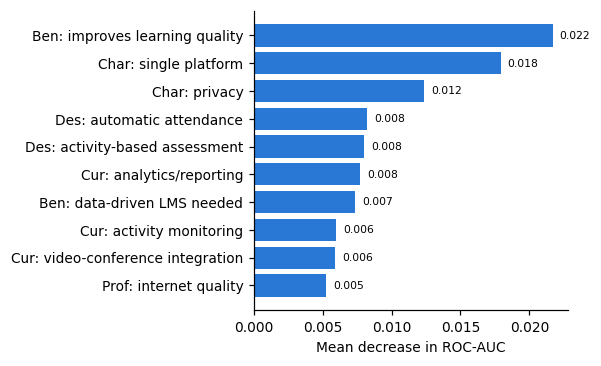

Total importance per kelompok: {'Cur': np.float64(0.0249), 'Des': np.float64(0.0258), 'Ben': np.float64(0.0292), 'Prof': np.float64(0.0095), 'Gap': np.float64(0.0033), 'Pri': np.float64(-0.0027), 'Char': np.float64(0.0304)}


In [37]:
best_tuned = exp3.roc_auc_mean.idxmax(); grid = GRIDS[best_tuned]; feats = FEATURE_SETS[BEST_FS]
imp = np.zeros(len(feats)); cnt = 0
for tr, te in StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(XA, yA):
    gs = GridSearchCV(Pipeline([('scale', StandardScaler()), ('model', algorithms()[best_tuned])]), grid,
                      cv=StratifiedKFold(3, shuffle=True, random_state=SEED), scoring='roc_auc', n_jobs=N_JOBS).fit(XA[tr], yA[tr])
    pi = permutation_importance(gs.best_estimator_, XA[te], yA[te], scoring='roc_auc', n_repeats=30, random_state=SEED, n_jobs=N_JOBS)
    imp += pi.importances_mean; cnt += 1
importance = pd.Series(imp / cnt, index=feats).sort_values(ascending=False)
print('Model:', best_tuned); print(importance.head(12).round(4))
top = importance.head(10)[::-1]
fig, ax = plt.subplots(figsize=(5.5, 3.4))
ax.barh(top.index, top.values, color='#2a78d6'); ax.set_xlabel('Mean decrease in ROC-AUC')
for y, v in enumerate(top.values): ax.text(v + 0.0005, y, f'{v:.3f}', va='center', fontsize=7)
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/fig_importance.png', dpi=300); plt.show()
group_imp = {g: importance[[f for f in feats if f.startswith(g)]].sum() for g in ['Cur', 'Des', 'Ben', 'Prof', 'Gap', 'Pri', 'Char']}
print('Total importance per kelompok:', {k: round(v, 4) for k, v in group_imp.items()})

## 10. Eksperimen 4 — Penjelasan model dengan SHAP

*Permutation importance* menunjukkan **seberapa penting** sebuah fitur, tetapi tidak menunjukkan **arah** pengaruhnya.
SHAP (*SHapley Additive exPlanations*) menguraikan setiap prediksi menjadi kontribusi per fitur, sehingga terlihat apakah nilai fitur yang tinggi
menaikkan atau menurunkan peluang kesediaan sangat kuat. Model berbasis pohon terbaik hasil *tuning* dilatih ulang pada seluruh data dengan
hyperparameter yang paling sering terpilih, lalu dijelaskan dengan `TreeExplainer`.

Model dijelaskan: CAT {'depth': 3, 'l2_leaf_reg': 10, 'learning_rate': 0.03}
                                         mean_abs_shap  direction_rho
Char: privacy                                    0.269          0.839
Ben: improves learning quality                   0.268          0.896
Char: single platform                            0.221          0.847
Ben: data-driven LMS needed                      0.129          0.888
Des: automatic attendance                        0.125          0.818
Des: activity-based assessment                   0.120          0.899
Ben: LMS-meeting integration                     0.117          0.726
Des: deadline management                         0.114          0.607
Prof: LMS use < 1 year                           0.110         -0.815
Cur: analytics/reporting                         0.093          0.235
Cur: video-conference integration                0.088         -0.356
Ben: collaboration improves interaction          0.067          0.888
Prof: laptop 

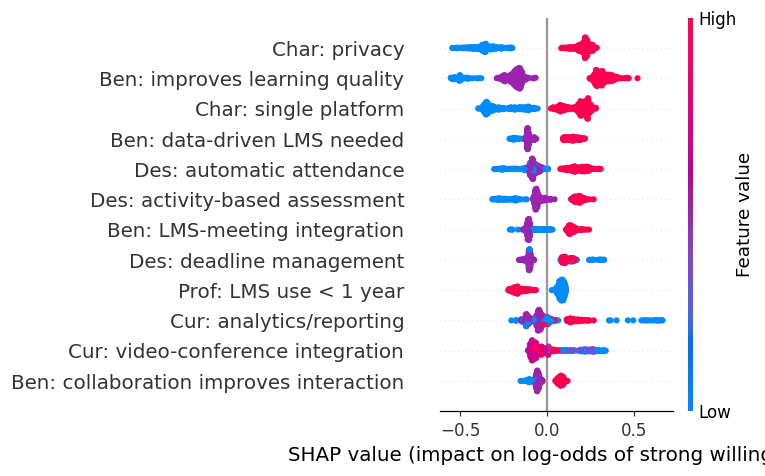

In [38]:
import ast
TREE = ['RF', 'GB', 'CAT']
shap_alg = best_tuned if best_tuned in TREE else exp3.loc[TREE].roc_auc_mean.idxmax()
p_ = {k.replace('model__', ''): v for k, v in ast.literal_eval(chosen[shap_alg]).items()}
shap_model = algorithms()[shap_alg].set_params(**p_).fit(XA, yA)          # pohon tidak terpengaruh standardisasi
expl = shap.TreeExplainer(shap_model)
sv = expl.shap_values(XA)
sv = np.asarray(sv)
if sv.ndim == 3: sv = sv[:, :, 1] if sv.shape[2] == 2 else sv[1]
Xdf = pd.DataFrame(XA, columns=feats)
mean_abs = pd.Series(np.abs(sv).mean(axis=0), index=feats).sort_values(ascending=False)
direction = pd.Series({f: stats.spearmanr(Xdf[f], sv[:, i]).correlation if Xdf[f].nunique() > 1 else np.nan
                       for i, f in enumerate(feats)})
shap_tab = pd.DataFrame({'mean_abs_shap': mean_abs, 'direction_rho': direction[mean_abs.index]})
print('Model dijelaskan:', shap_alg, p_); print(shap_tab.head(15).round(3))
grp = {g: mean_abs[[f for f in feats if f.startswith(g)]].sum() for g in ['Cur', 'Des', 'Ben', 'Prof', 'Gap', 'Pri', 'Char']}
grp_share = {g: v / sum(grp.values()) for g, v in grp.items()}
print('Porsi |SHAP| per kelompok:', {k: round(v, 3) for k, v in grp_share.items()})
# konsistensi dengan permutation importance (top-10)
top10_overlap = len(set(mean_abs.index[:10]) & set(importance.index[:10]))
rho_imp = stats.spearmanr(mean_abs[feats], importance[feats]).correlation
print('Irisan top-10 SHAP vs permutation:', top10_overlap, '| Spearman seluruh fitur:', round(rho_imp, 3))
plt.figure()
shap.summary_plot(sv, Xdf, max_display=12, show=False, plot_size=(7.0, 4.4), color_bar_label='Feature value')
plt.xlabel('SHAP value (impact on log-odds of strong willingness)'); plt.tight_layout()
plt.savefig(f'{OUT_DIR}/fig_shap.png', dpi=300, bbox_inches='tight'); plt.show()

## 11. Eksperimen 5 — Ablasi kelompok fitur

Setiap kelompok fitur dihapus satu per satu (*leave-one-group-out*) dan model terbaik pada eksperimen 1 dilatih ulang dengan fold yang sama.
Penurunan AUC menunjukkan kontribusi unik kelompok tersebut; nilai mendekati nol berarti informasinya sudah diwakili kelompok lain.
Perbedaan diuji dengan *corrected resampled t-test*. Juga dilaporkan AUC jika **hanya** kelompok itu yang dipakai.

Model: RF; AUC semua fitur = 0.777
                          group n_features  auc_without    drop       t  \
Cur      Current LMS conditions          7       0.7746  0.0027  0.2219   
Des            Desired features          9       0.7643  0.0130  1.1042   
Ben          Perceived benefits          5       0.7650  0.0122  1.0591   
Prof               User profile          9       0.7733  0.0040  0.6216   
Gap           Reported problems          8       0.7802 -0.0029 -0.4555   
Pri          Feature priorities         10       0.7733  0.0040  0.6691   
Char  Ideal LMS characteristics          8       0.7620  0.0153  1.7406   

           p  auc_only  
Cur   0.8263    0.6366  
Des   0.2805    0.6885  
Ben   0.3001    0.6876  
Prof  0.5401    0.5758  
Gap   0.6529    0.5399  
Pri   0.5098    0.5611  
Char  0.0946    0.5689  


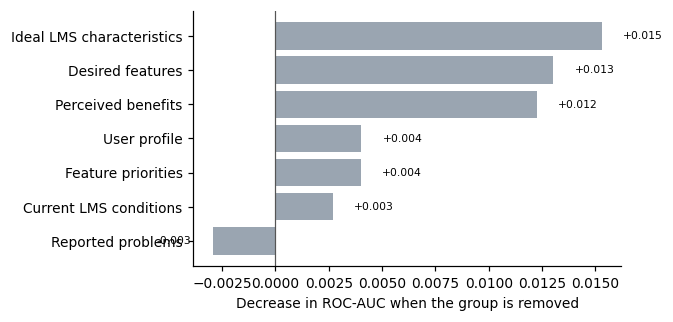

In [39]:
GROUPS = {'Cur': 'Current LMS conditions', 'Des': 'Desired features', 'Ben': 'Perceived benefits', 'Prof': 'User profile',
          'Gap': 'Reported problems', 'Pri': 'Feature priorities', 'Char': 'Ideal LMS characteristics'}
full = exp1_folds[(BEST_FS, best_alg)]; ablation = {}
for g, gname in GROUPS.items():
    keep_cols = [f for f in feats if not f.startswith(g)]; only_cols = [f for f in feats if f.startswith(g)]
    r_drop = cross_validate(Pipeline([('scale', StandardScaler()), ('model', algorithms()[best_alg])]),
                            data[keep_cols].values.astype(float), yA, cv=CV, scoring='roc_auc', n_jobs=N_JOBS)['test_score']
    r_only = cross_validate(Pipeline([('scale', StandardScaler()), ('model', algorithms()[best_alg])]),
                            data[only_cols].values.astype(float), yA, cv=CV, scoring='roc_auc', n_jobs=N_JOBS)['test_score']
    t, p = nb_corrected_t(full, r_drop)
    ablation[g] = {'group': gname, 'n_features': len(only_cols), 'auc_without': r_drop.mean(), 'drop': full.mean() - r_drop.mean(),
                   't': t, 'p': p, 'auc_only': r_only.mean()}
abl = pd.DataFrame(ablation).T; abl[['auc_without', 'drop', 't', 'p', 'auc_only']] = abl[['auc_without', 'drop', 't', 'p', 'auc_only']].astype(float)
print(f'Model: {best_alg}; AUC semua fitur = {full.mean():.3f}'); print(abl.round(4))
a_ = abl.sort_values('drop')
fig, ax = plt.subplots(figsize=(6.2, 3.0))
ax.barh(a_.group, a_['drop'], color=['#eb6834' if p < 0.05 else '#9aa5b1' for p in a_.p])
ax.axvline(0, color='#555', lw=0.8); ax.set_xlabel('Decrease in ROC-AUC when the group is removed')
for y, (v, p) in enumerate(zip(a_['drop'], a_.p)): ax.text(v + (0.001 if v >= 0 else -0.001), y, f'{v:+.3f}' + ('*' if p < 0.05 else ''),
                                                       va='center', ha='left' if v >= 0 else 'right', fontsize=7)
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/fig_ablation.png', dpi=300); plt.show()

## 12. Eksperimen 6 — Kalibrasi probabilitas dan pemilihan ambang (target 2)

Resampling mengubah proporsi kelas di data latih, sehingga probabilitas yang dihasilkan cenderung **terlalu tinggi** untuk kelas minoritas.
Dibandingkan tiga varian pada kombinasi terbaik eksperimen 2:
1. **Raw** — probabilitas langsung, ambang 0,5.
2. **Recalibrated** — `CalibratedClassifierCV` (sigmoid, 3-fold di dalam data latih), ambang 0,5.
3. **Tuned threshold** — ambang dipilih **di dalam data latih** (prediksi *out-of-fold* internal) untuk memaksimalkan *balanced accuracy*, lalu diterapkan ke data uji.
4. **Recalibrated + tuned threshold** — probabilitas terkalibrasi dengan ambang yang dipilih dengan cara yang sama.

Semua dievaluasi dengan 5-fold × 5 ulangan yang sama.

In [40]:
def make_best2(cal=False):
    s, a = best2.sampler, best2.algorithm
    if s == 'CW': steps = [('scale', StandardScaler()), ('model', cw_model(a))]
    else: steps = [('scale', StandardScaler())] + ([('sample', SAMPLERS[s])] if SAMPLERS[s] is not None else []) + [('model', algorithms()[a])]
    pipe = Pipeline(steps)
    return CalibratedClassifierCV(pipe, method='sigmoid', cv=3) if cal else pipe
rows = {'Raw (threshold 0.5)': [], 'Recalibrated (threshold 0.5)': [], 'Tuned threshold': [], 'Recalibrated + tuned threshold': []}
oof_raw, oof_cal, n_seen = np.zeros(len(yB)), np.zeros(len(yB)), np.zeros(len(yB)); thr_chosen = []; thr_cal = []
def mets(y, p, thr):
    yh = (p >= thr).astype(int)
    return {'balanced_accuracy': balanced_accuracy_score(y, yh), 'recall_minority': recall_score(y, yh, zero_division=0),
            'precision_minority': precision_score(y, yh, zero_division=0), 'f1_minority': f1_score(y, yh, zero_division=0),
            'mcc': matthews_corrcoef(y, yh), 'brier': brier_score_loss(y, p), 'roc_auc': roc_auc_score(y, p)}
t0 = time.time()
for tr, te in CV.split(XB, yB):
    m_raw = make_best2().fit(XB[tr], yB[tr]); p_raw = m_raw.predict_proba(XB[te])[:, 1]
    m_cal = make_best2(cal=True).fit(XB[tr], yB[tr]); p_cal = m_cal.predict_proba(XB[te])[:, 1]
    inner_p = cross_val_predict(make_best2(), XB[tr], yB[tr], cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method='predict_proba')[:, 1]
    grid_t = np.unique(np.quantile(inner_p, np.linspace(0.02, 0.98, 49)))
    thr = grid_t[np.argmax([balanced_accuracy_score(yB[tr], (inner_p >= t).astype(int)) for t in grid_t])]; thr_chosen.append(thr)
    rows['Raw (threshold 0.5)'].append(mets(yB[te], p_raw, 0.5)); rows['Recalibrated (threshold 0.5)'].append(mets(yB[te], p_cal, 0.5))
    rows['Tuned threshold'].append(mets(yB[te], p_raw, thr))
    inner_pc = cross_val_predict(make_best2(cal=True), XB[tr], yB[tr], cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method='predict_proba')[:, 1]
    grid_c = np.unique(np.quantile(inner_pc, np.linspace(0.02, 0.98, 49)))
    thr_c = grid_c[np.argmax([balanced_accuracy_score(yB[tr], (inner_pc >= t).astype(int)) for t in grid_c])]; thr_cal.append(thr_c)
    rows['Recalibrated + tuned threshold'].append(mets(yB[te], p_cal, thr_c))
    oof_raw[te] += p_raw; oof_cal[te] += p_cal; n_seen[te] += 1
oof_raw /= n_seen; oof_cal /= n_seen
calib = {k: pd.DataFrame(v).mean().to_dict() for k, v in rows.items()}
calib_sd = {k: pd.DataFrame(v).std().to_dict() for k, v in rows.items()}
print(f'Kombinasi: {best2.sampler} + {best2.algorithm} | {time.time()-t0:.0f} detik | median ambang raw = {np.median(thr_chosen):.3f}, kalibrasi = {np.median(thr_cal):.3f}')
print('Brier tanpa keahlian (prevalensi):', round(yB.mean() * (1 - yB.mean()), 4))
print('Prevalensi minoritas:', round(yB.mean(), 3), '| rata-rata prob. raw:', round(oof_raw.mean(), 3), '| rata-rata prob. kalibrasi:', round(oof_cal.mean(), 3))
pd.DataFrame(calib).T.round(3)

Kombinasi: RUS + NB | 1 detik | median ambang raw = 0.384, kalibrasi = 0.104
Brier tanpa keahlian (prevalensi): 0.0826
Prevalensi minoritas: 0.091 | rata-rata prob. raw: 0.347 | rata-rata prob. kalibrasi: 0.093


,balanced_accuracy,recall_minority,precision_minority,f1_minority,mcc,brier,roc_auc
Raw (threshold 0.5),0.661,0.638,0.169,0.266,0.196,0.282,0.734
Recalibrated (threshold 0.5),0.500,0.000,0.000,0.000,0.000,0.079,0.736
Tuned threshold,0.657,0.631,0.186,0.271,0.203,0.282,0.734
Recalibrated + tuned threshold,0.646,0.614,0.166,0.255,0.181,0.079,0.736


## 13. Eksperimen 7 — Keadilan performa antara dosen dan mahasiswa

Prediksi *out-of-fold* (rata-rata dari 5 ulangan 5-fold) dipisahkan menurut peran. Selang kepercayaan 95% dihitung dengan *bootstrap* (2000 sampel).
Untuk target 2, prediksi memakai varian *tuned threshold* dari eksperimen 6.

In [41]:
def oof_proba(make_pipe, X, y, reps=5):
    p = np.zeros(len(y))
    for r in range(reps):
        p += cross_val_predict(make_pipe(), X, y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED + r), method='predict_proba')[:, 1]
    return p / reps
pA = oof_proba(lambda: Pipeline([('scale', StandardScaler()), ('model', algorithms()[best_alg])]), XA, yA)
is_lec_d = data['Prof: lecturer'].values == 1
rng = np.random.default_rng(SEED)
def boot(fn, y, p, B=2000):
    vals = []
    for _ in range(B):
        i = rng.integers(0, len(y), len(y))
        if len(np.unique(y[i])) < 2: continue
        vals.append(fn(y[i], p[i]))
    return np.percentile(vals, [2.5, 97.5])
fair = {}
thr_med = float(np.median(thr_chosen))
for name, mask in [('Lecturers', is_lec_d), ('Students', ~is_lec_d), ('All', np.ones(len(yA), bool))]:
    yA_, pA_ = yA[mask], pA[mask]; yB_, pB_ = yB[mask], oof_raw[mask]
    fair[name] = {'n': int(mask.sum()), 'posA': int(yA_.sum()), 'aucA': roc_auc_score(yA_, pA_), 'aucA_ci': boot(roc_auc_score, yA_, pA_),
                  'baccA': balanced_accuracy_score(yA_, (pA_ >= 0.5).astype(int)),
                  'posB': int(yB_.sum()), 'aucB': roc_auc_score(yB_, pB_) if yB_.sum() > 0 else np.nan,
                  'recallB': recall_score(yB_, (pB_ >= thr_med).astype(int), zero_division=0) if yB_.sum() > 0 else np.nan,
                  'fprB': float(((pB_ >= thr_med) & (yB_ == 0)).sum() / max((yB_ == 0).sum(), 1))}
pd.DataFrame(fair).T

,n,posA,aucA,aucA_ci,baccA,posB,aucB,recallB,fprB
Lecturers,113,66,0.765796,"[0.6756599926812693, 0.8533444213444213]",0.688749,7,0.702156,0.571429,0.254717
Students,426,191,0.765211,"[0.7196703031490742, 0.8108832710488587]",0.686967,42,0.749535,0.690476,0.375
All,539,257,0.770242,"[0.7295607378423244, 0.8081788889039838]",0.694904,49,0.744627,0.673469,0.34898


## 14. Eksperimen 8 — *Learning curve*

Apakah performa masih naik bila data ditambah? Kurva dibuat untuk tiga algoritma dengan karakter berbeda (RF, LR, NB) pada set fitur terbaik.

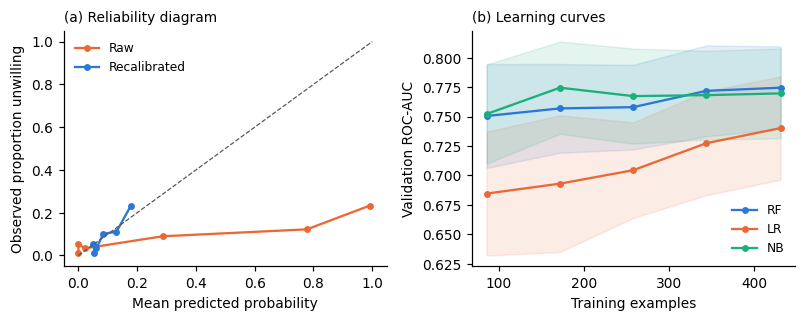

{'RF': [0.75, 0.757, 0.758, 0.772, 0.775], 'LR': [0.685, 0.693, 0.704, 0.727, 0.74], 'NB': [0.752, 0.775, 0.767, 0.768, 0.77]} | ukuran: [86, 172, 258, 344, 431]


In [42]:
sizes = np.linspace(0.2, 1.0, 5); lc = {}
fig, axes = plt.subplots(1, 2, figsize=(7.4, 3.0))
for a, c in zip([best_alg, 'LR', 'NB'], ['#2a78d6', '#eb6834', '#1baf7a']):
    ts, tr_s, te_s = learning_curve(Pipeline([('scale', StandardScaler()), ('model', algorithms()[a])]), XA, yA, train_sizes=sizes,
                                    cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED), scoring='roc_auc', n_jobs=N_JOBS)
    lc[a] = {'train_size': ts.tolist(), 'test_auc': te_s.mean(axis=1).tolist(), 'test_sd': te_s.std(axis=1).tolist(), 'train_auc': tr_s.mean(axis=1).tolist()}
    axes[1].plot(ts, te_s.mean(axis=1), 'o-', color=c, ms=3.5, label=a)
    axes[1].fill_between(ts, te_s.mean(axis=1) - te_s.std(axis=1), te_s.mean(axis=1) + te_s.std(axis=1), color=c, alpha=0.12)
axes[1].set_xlabel('Training examples'); axes[1].set_ylabel('Validation ROC-AUC'); axes[1].legend(frameon=False, fontsize=8); axes[1].set_title('(b) Learning curves', fontsize=9, loc='left')
for pp, lab, c in [(oof_raw, 'Raw', '#eb6834'), (oof_cal, 'Recalibrated', '#2a78d6')]:
    fp, mp = calibration_curve(yB, pp, n_bins=6, strategy='quantile'); axes[0].plot(mp, fp, 'o-', color=c, ms=3.5, label=lab)
axes[0].plot([0, 1], [0, 1], ls='--', color='#555', lw=0.8); axes[0].set_xlabel('Mean predicted probability'); axes[0].set_ylabel('Observed proportion unwilling')
axes[0].legend(frameon=False, fontsize=8); axes[0].set_title('(a) Reliability diagram', fontsize=9, loc='left')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/fig_calib_lc.png', dpi=300); plt.show()
print({a: [round(v, 3) for v in d['test_auc']] for a, d in lc.items()}, '| ukuran:', lc[best_alg]['train_size'])

## 15. Ekspor hasil

In [43]:
def clean(o):
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, np.floating): return float(o)
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.ndarray): return clean(o.tolist())
    return o
results = {'audit': audit, 'n': int(len(data)), 'n_features': {k: len(v) for k, v in FEATURE_SETS.items()},
           'targetA_pos': int(yA.sum()), 'targetB_pos': int(yB.sum()), 'exp1': exp1.to_dict(orient='records'),
           'fs_mean_auc': fs_mean.to_dict(), 'alg_mean_auc': alg_mean.to_dict(), 'best_fs': BEST_FS,
           'best_combo': best_combo.to_dict(), 'friedman': {'chi2': fried.statistic, 'p': fried.pvalue, 'df': k - 1, 'CD': CD, 'q_alpha': q_alpha},
           'avg_rank': avg_rank.to_dict(), 'best_rank_alg': best_alg, 'nadeau_bengio': nb_tests,
           'exp2': exp2.to_dict(orient='records'), 'exp2_by_sampler': exp2.groupby('sampler')[['balanced_accuracy_mean', 'f1_minority_mean', 'mcc_mean', 'pr_auc_mean', 'accuracy_mean']].mean().to_dict(orient='index'),
           'best2': best2.to_dict(), 'exp3': exp3.reset_index().to_dict(orient='records'), 'best_tuned': best_tuned,
           'importance': importance.to_dict(), 'group_importance': group_imp, 'chosen_params': chosen,
           'shap_alg': shap_alg, 'shap_params': p_, 'shap': shap_tab.head(20).to_dict(orient='index'), 'shap_group_share': grp_share,
           'shap_top10_overlap': top10_overlap, 'shap_perm_rho': rho_imp,
           'ablation': abl.to_dict(orient='index'), 'ablation_full_auc': full.mean(),
           'calibration': calib, 'calibration_sd': calib_sd, 'threshold_median': thr_med, 'threshold_iqr': np.percentile(thr_chosen, [25, 75]), 'threshold_cal_median': np.median(thr_cal), 'threshold_cal_iqr': np.percentile(thr_cal, [25, 75]), 'brier_noskill': yB.mean() * (1 - yB.mean()),
           'mean_prob_raw': oof_raw.mean(), 'mean_prob_cal': oof_cal.mean(), 'prevalence_B': yB.mean(),
           'fairness': fair, 'learning_curve': lc}
json.dump(clean(results), open(f'{OUT_DIR}/results_resti2.json', 'w'), indent=1)
exp1.to_csv(f'{OUT_DIR}/exp1_algorithm_x_featureset.csv', index=False); exp2.to_csv(f'{OUT_DIR}/exp2_algorithm_x_sampler.csv', index=False)
exp3.to_csv(f'{OUT_DIR}/exp3_nested_tuning.csv'); print(os.listdir(OUT_DIR))

['fig_importance.png', 'results_resti2.json', 'fig_shap.png', 'fig_imbalance.png', 'fig_ablation.png', 'fig_calib_lc.png', 'exp1_algorithm_x_featureset.csv', 'exp2_algorithm_x_sampler.csv', 'fig_heatmap_auc.png', 'fig_cd.png', 'exp3_nested_tuning.csv']
